# Spectral Embedding, Clustering & Peak Calling

In [1]:
import gatac as ga
import scanpy as sc
import rapids_singlecell as rsc
import anndata as ad
import time

sc.set_figure_params(dpi=100, frameon=False)

adata = ad.read_h5ad("data/pbmc_tile.h5ad")
print(adata)

AnnData object with n_obs × n_vars = 5001 × 500000
    obs: 'barcode', 'source_file', 'n_unique', 'tsse_score', 'duplicate_fraction', 'mito_fraction'
    var: 'chrom', 'start', 'end', 'n_cells', 'count', 'count_sq', 'selected', 'accessibility_count'
    uns: 'tile_scan', 'tile_stats'


## 1. Spectral embedding

Compute a spectral decomposition of the TF-IDF-normalised cell × tile matrix.
The resulting components are stored in `adata.obsm["X_spectral"]`.

In [2]:
t0 = time.perf_counter()
ga.dr.spectral(adata, n_comps=30)
print(f"Spectral embedding in {time.perf_counter() - t0:.1f}s")
print(f"Embedding shape: {adata.obsm['X_spectral'].shape}")

11:19:58 - gatac.dr.spectral - INFO - Running GPU-accelerated spectral embedding ...


11:20:22 - gatac.dr.spectral - INFO - IDF weights computed.


11:20:22 - gatac.dr.spectral - INFO - Row normalization done.


11:20:22 - gatac.dr.spectral - INFO - Eigen-decomposition done.


11:20:22 - gatac.dr.spectral - INFO - Spectral embedding complete: 30 components (top eigenvalue = 1.0000).


Spectral embedding in 23.8s
Embedding shape: (5001, 30)


## 2. UMAP & Leiden clustering

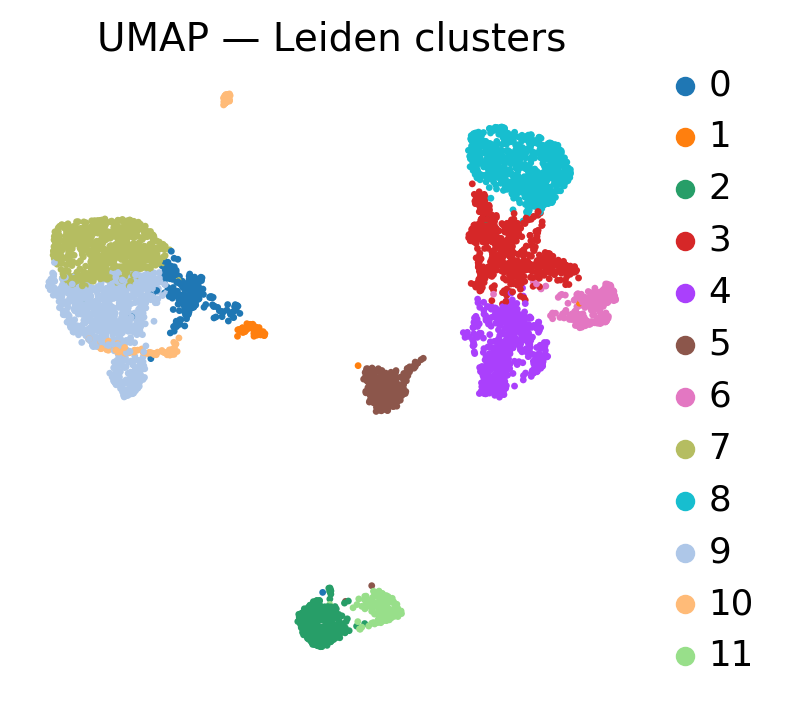

In [3]:
rsc.pp.neighbors(adata, use_rep="X_spectral", n_neighbors=30)
rsc.tl.umap(adata, min_dist=0.3)
rsc.tl.leiden(adata, resolution=0.5)

sc.pl.umap(adata, color="leiden",
           title="UMAP — Leiden clusters")

## 3. Annotate cell types from gene activity

A gene activity matrix counts the Tn5 insertions over each gene body and its
promoter (`ga.pp.make_gene_matrix`). After normalisation, every cell gets a
score for each lineage from a few canonical marker genes, and each cluster
takes the lineage it scores highest for, provided that lineage stands out
(z-score above 0.75 across clusters). Clusters with no clear lineage are labelled
`Other`.

11:20:24 - gatac.pp.gene - INFO - Loading gene annotation from data/gencode.v44.primary_assembly.annotation.gtf.gz


11:20:26 - gatac.pp.gene - INFO - Loaded 244,742 transcript regulatory domains (for gene-level output)


11:20:26 - gatac.pp.gene - INFO - Processing pbmc_fragments.parquet


11:20:51 - gatac.pp.gene - INFO - Using uint16 dtype (max count: 1233)


11:20:51 - gatac.pp.gene - INFO - Gene matrix: 5,543 cells × 61,267 genes (25.8s)


Gene activity matrix in 28.2s


... storing 'chrom' as categorical


... storing 'strand' as categorical


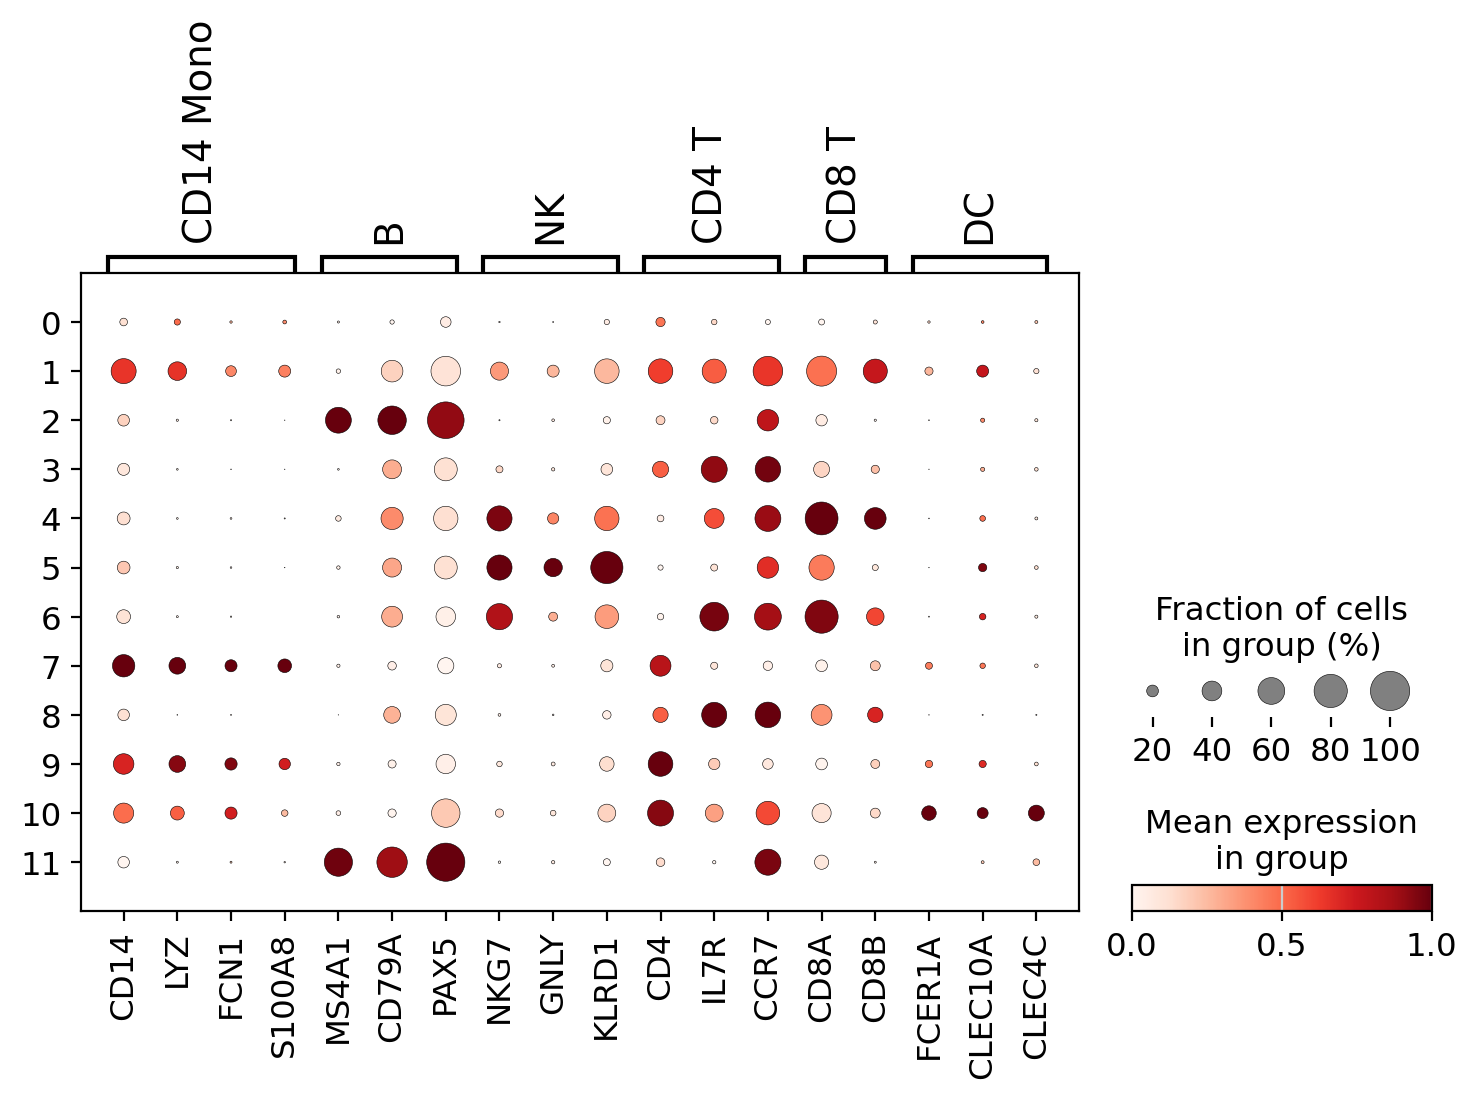

In [4]:
import pandas as pd

MARKERS = {
    "CD14 Mono": ["CD14", "LYZ", "FCN1", "S100A8"],
    "B": ["MS4A1", "CD79A", "PAX5"],
    "NK": ["NKG7", "GNLY", "KLRD1"],
    "CD4 T": ["CD4", "IL7R", "CCR7"],
    "CD8 T": ["CD8A", "CD8B"],
    "DC": ["FCER1A", "CLEC10A", "CLEC4C"],
}

# Every cell kept by the QC of notebook 01 has at least 1,500 unique fragments
t0 = time.perf_counter()
gene_adata = ga.pp.make_gene_matrix(
    "data/pbmc_fragments.parquet",
    "data/gencode.v44.primary_assembly.annotation.gtf.gz",
    min_fragments_per_cell=1000,
)[adata.obs_names].copy()
print(f"Gene activity matrix in {time.perf_counter() - t0:.1f}s")

sc.pp.normalize_total(gene_adata, target_sum=1e4)
sc.pp.log1p(gene_adata)
gene_adata.obs["leiden"] = adata.obs["leiden"].values
sc.pl.dotplot(gene_adata, MARKERS, groupby="leiden", standard_scale="var")

In [5]:
for name, genes in MARKERS.items():
    sc.tl.score_genes(gene_adata, genes, score_name=name, random_state=0)
scores = gene_adata.obs.groupby("leiden", observed=True)[list(MARKERS)].mean()
z = (scores - scores.mean()) / scores.std()
labels = z.idxmax(axis=1).where(z.max(axis=1) > 0.75, "Other")

adata.obs["cell_type"] = pd.Categorical(adata.obs["leiden"].map(labels))
z.round(2).assign(cell_type=labels)

,CD14 Mono,B,NK,CD4 T,CD8 T,DC,cell_type
leiden,,,,,,,
0,0.42,-0.36,-0.49,-0.51,-0.47,-0.27,Other
1,0.62,-0.53,0.00,-0.03,0.55,-0.11,Other
2,-0.65,2.10,-0.66,-0.30,-0.76,-0.34,B
3,-0.70,-0.29,-0.33,1.62,-0.39,-0.50,CD4 T
4,-0.58,-0.19,1.23,-0.01,2.09,-0.22,CD8 T
5,-0.58,-0.23,2.49,-1.29,0.17,0.07,NK
6,-0.63,-0.46,0.79,0.65,1.58,-0.02,CD8 T
7,2.26,-0.69,-0.62,-1.18,-0.78,-0.24,CD14 Mono
8,-0.59,-0.34,-0.53,1.91,0.47,-1.05,CD4 T


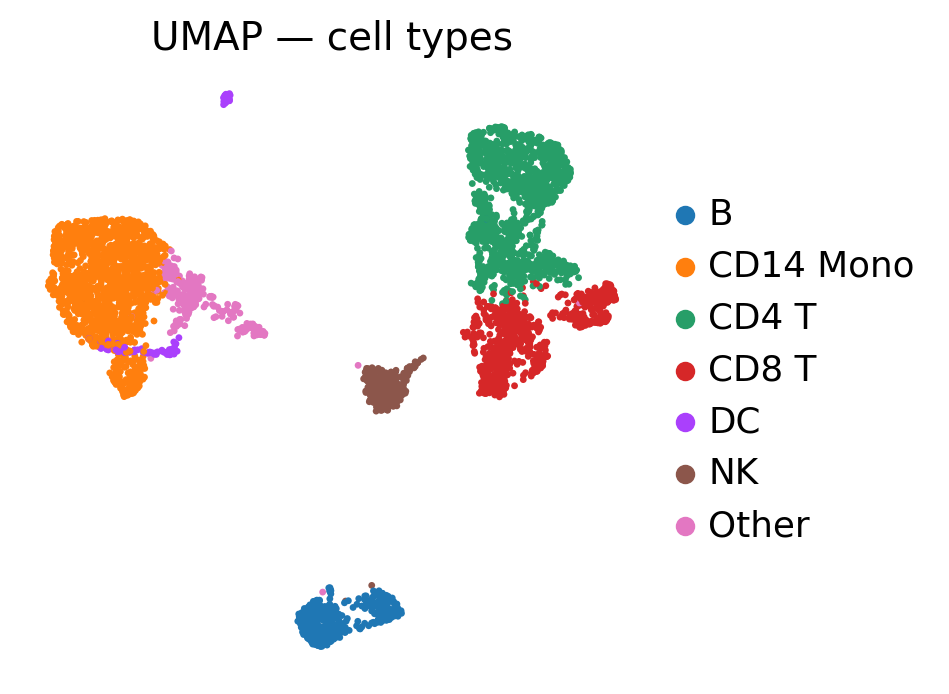

In [6]:
sc.pl.umap(adata, color="cell_type", title="UMAP — cell types")

## 4. Call peaks per cluster

For each Leiden cluster we call peaks with a GPU port of MACS3 `callpeak`, which gives the same peaks as SnapATAC2's `macs3`.

In [7]:
t0 = time.perf_counter()
ga.peak.call(
    adata,
    groupby="leiden",
    parquet_path="data/pbmc_fragments.parquet",
    genome="hg38",
)
print(f"Peak calling in {time.perf_counter() - t0:.1f}s")

11:20:59 - gatac.peak.peaks - INFO - Using genome length: 3,088,269,832 bp


11:20:59 - gatac.peak.peaks - INFO - Calling peaks for 12 groups in 'leiden'


Reading files:   0%|          | 0/1 [00:00<?, ?it/s]

Groups:   0%|          | 0/12 [00:00<?, ?it/s]

11:21:01 - gatac.peak.peaks - INFO - Group 0: 2,046,749 fragments, calling peaks...


...

11:21:09 - gatac.peak.peaks - INFO - Group 7: 12,248,214 fragments, calling peaks...


11:21:10 - gatac.peak.peaks - INFO -   Found 106,947 summits


11:21:10 - gatac.peak.peaks - INFO - Group 9: 15,799,383 fragments, calling peaks...


11:21:12 - gatac.peak.peaks - INFO -   Found 120,443 summits


Peak calling in 12.2s


In [8]:
# Number of peaks per cluster
for group, peak_df in adata.uns["gmacs"].items():
    print(f"  Cluster {group}: {len(peak_df):,} peaks")


  Cluster 6: 53,473 peaks
  Cluster 4: 67,429 peaks
  Cluster 7: 106,947 peaks
  Cluster 8: 62,950 peaks
  Cluster 3: 65,475 peaks
  Cluster 11: 60,806 peaks
  Cluster 2: 67,921 peaks
  Cluster 9: 120,443 peaks
  Cluster 10: 85,321 peaks
  Cluster 0: 56,147 peaks
  Cluster 5: 65,455 peaks
  Cluster 1: 69,459 peaks


## 5. Merge peaks across clusters

In [9]:
ga.peak.merge(adata,chrom_sizes="hg38")
adata.uns["peaks"]

,chrom,start,end,name,score,strand,signal_value,p_value,q_value,peak
586906,chr7,23013966,23014467,.,1000,.,26.100498,1268.687500,1260.559692,250
587525,chr7,36152781,36153282,.,1000,.,21.323997,1236.863647,1229.219238,250
272913,chr4,83034794,83035295,.,1000,.,26.690552,1215.144775,1207.765869,250
284754,chr8,41490171,41490672,.,1000,.,25.973742,1196.283081,1189.173828,250
557996,chr22,29603231,29603732,.,1000,.,25.703159,1191.965942,1184.946289,250
...,...,...,...,...,...,...,...,...,...,...
591890,chr8,2046286,2046787,.,13,.,2.678571,3.114960,1.331991,250
485050,chr1,1124109,1124610,.,13,.,2.162850,3.111930,1.329267,250
529593,chr17,2361758,2362259,.,13,.,2.662722,3.089600,1.307714,250
566626,chr3,187719818,187720319,.,13,.,2.662722,3.089600,1.307714,250


## 6. Build cell × peak matrix

In [10]:
t0 = time.perf_counter()
peak_adata = ga.peak.make_matrix(
    adata,parquet_path="data/pbmc_fragments.parquet",
)
print(f"Peak matrix built in {time.perf_counter() - t0:.1f}s")
print(peak_adata)

11:21:12 - gatac.peak.peaks - INFO - Counting fragments in 179,702 peaks


11:21:12 - gatac.peak.peaks - INFO - Processing single parquet file


Parquet files:   0%|          | 0/1 [00:00<?, ?it/s]

11:21:13 - gatac.pp.gene - INFO - Using uint8 dtype (max count: 67)


11:21:13 - gatac.peak.peaks - INFO - Peak matrix: 5,001 cells × 179,702 peaks


11:21:13 - gatac.peak.peaks - INFO - Sparsity: 95.05%


Peak matrix built in 1.3s
AnnData object with n_obs × n_vars = 5001 × 179702
    obs: 'barcode', 'source_file', 'n_unique', 'tsse_score', 'duplicate_fraction', 'mito_fraction', 'leiden', 'cell_type'


## 7. Save

In [11]:
# Keep the UMAP with the peak matrix, for plotting in the next notebooks
peak_adata.obsm["X_umap"] = adata[peak_adata.obs_names].obsm["X_umap"]
peak_adata.write_h5ad("data/pbmc_peaks.h5ad")
print("Saved → data/pbmc_peaks.h5ad")

Saved → data/pbmc_peaks.h5ad


## Next steps

- [03 – Motif enrichment](03_motif_enrichment.ipynb)
- [04 – chromVAR](04_chromvar.ipynb)
- [06 – TF footprinting](06_footprinting.ipynb)